<div align="center">

# Assignment 2 — Logistic Regression

---

**Name:** Shreyas Sovani &nbsp;|&nbsp; **Roll No:** 22 &nbsp;|&nbsp; **Class:** AIML-F &nbsp;|&nbsp; **Subject:** Machine Learning

---

</div>


# Assignment 2 — Logistic Regression

**Dataset:** Titanic (`titanic.csv`)

**Objective:** Predict which passengers **survived** the Titanic disaster using logistic regression.

## 1. Theory

Logistic regression models the probability of a binary outcome using the sigmoid function:

$$P(y=1 \mid x) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_n x_n)}}$$

The output probability is thresholded (default 0.5) to produce a class label. Coefficients are interpreted as **odds ratios**: $e^{\beta_i}$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             roc_curve, roc_auc_score)

sns.set_theme(style='whitegrid')
%matplotlib inline

In [2]:
df = pd.read_csv('titanic.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
print('Shape:', df.shape)
df.info()

Shape: (891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


## 2. Exploratory Data Analysis

In [4]:
df['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

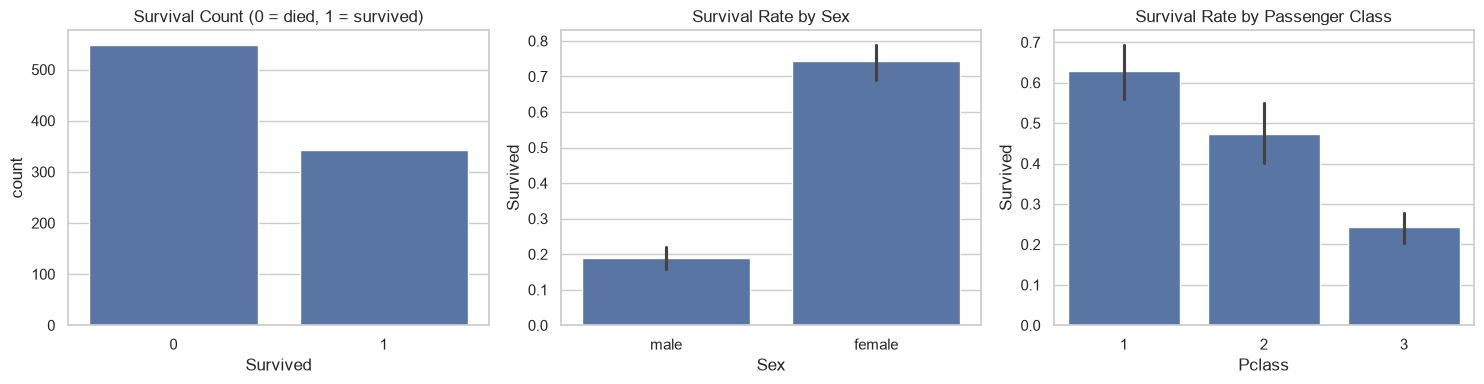

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(x='Survived', data=df, ax=axes[0])
axes[0].set_title('Survival Count (0 = died, 1 = survived)')

sns.barplot(x='Sex', y='Survived', data=df, ax=axes[1])
axes[1].set_title('Survival Rate by Sex')

sns.barplot(x='Pclass', y='Survived', data=df, ax=axes[2])
axes[2].set_title('Survival Rate by Passenger Class')

plt.tight_layout()
plt.show()

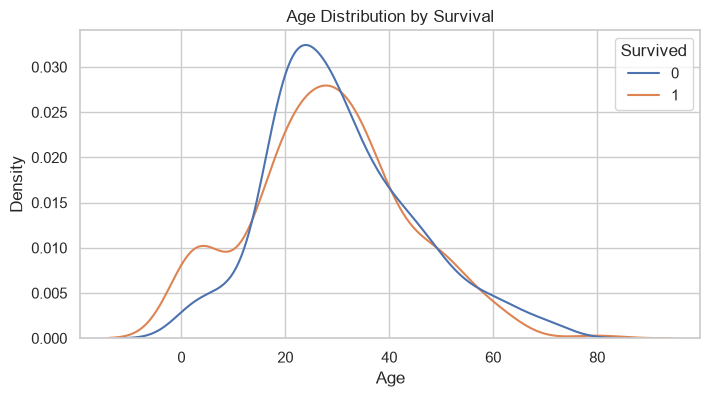

In [6]:
plt.figure(figsize=(8, 4))
sns.kdeplot(data=df, x='Age', hue='Survived', common_norm=False)
plt.title('Age Distribution by Survival')
plt.show()

Females and 1st-class passengers survived at much higher rates — these will be strong predictors.

## 3. Preprocessing

In [7]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [8]:
# Drop columns that are unusable as features
df = df.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1)

# Impute missing values
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# New feature: family size
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df = df.drop(['SibSp', 'Parch'], axis=1)

df.isnull().sum()

Survived      0
Pclass        0
Sex           0
Age           0
Fare          0
Embarked      0
FamilySize    0
dtype: int64

In [9]:
# One-hot encode categorical variables
df = pd.get_dummies(df, columns=['Sex', 'Embarked'], drop_first=True)
df.head()

,Survived,Pclass,Age,Fare,FamilySize,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.0,7.2500,2,True,False,True
1,1,1,38.0,71.2833,2,False,False,False
2,1,3,26.0,7.9250,1,False,False,True
3,1,1,35.0,53.1000,2,False,False,True
4,0,3,35.0,8.0500,1,True,False,True


In [10]:
X = df.drop('Survived', axis=1)
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (712, 7)  Test: (179, 7)


## 4. Train Logistic Regression

In [11]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0].round(3),
    'Odds Ratio': np.exp(model.coef_[0]).round(3)
})
coefficients

,Feature,Coefficient,Odds Ratio
0,Pclass,-0.925,0.397
1,Age,-0.494,0.610
2,Fare,0.104,1.110
3,FamilySize,-0.268,0.765
4,Sex_male,-1.279,0.278
5,Embarked_Q,0.074,1.077
6,Embarked_S,-0.176,0.838


Odds ratio > 1 increases survival chance, < 1 decreases it. Being female (`Sex_male = 0`) massively raises survival odds; higher class (negative coefficient on `Pclass`) helps too.

## 5. Evaluation

In [12]:
y_pred = model.predict(X_test_scaled)

print(f'Accuracy  : {accuracy_score(y_test, y_pred):.3f}')
print(f'Precision : {precision_score(y_test, y_pred):.3f}')
print(f'Recall    : {recall_score(y_test, y_pred):.3f}')
print(f'F1-score  : {f1_score(y_test, y_pred):.3f}')

Accuracy  : 0.799
Precision : 0.780
Recall    : 0.667
F1-score  : 0.719


In [13]:
print(classification_report(y_test, y_pred, target_names=['Died', 'Survived']))

              precision    recall  f1-score   support

        Died       0.81      0.88      0.84       110
    Survived       0.78      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.79      0.77      0.78       179
weighted avg       0.80      0.80      0.80       179



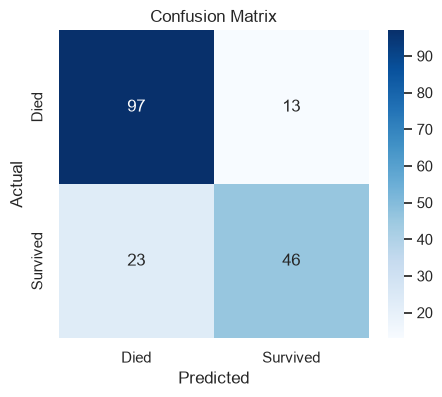

In [14]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Died', 'Survived'], yticklabels=['Died', 'Survived'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

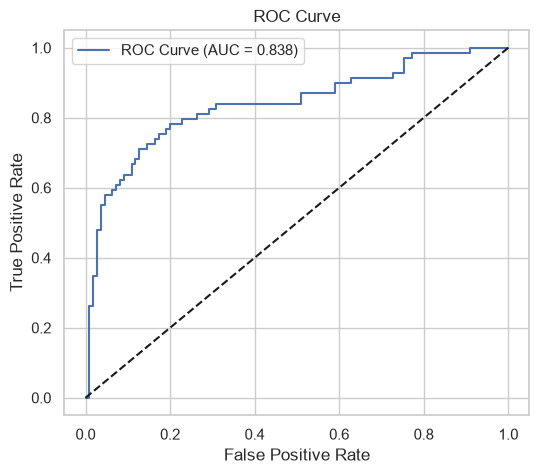

In [15]:
y_prob = model.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc_score(y_test, y_prob):.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

## 6. Prediction on a New Passenger

In [16]:
# 3rd-class male, age 25, fare 7.5, family size 1, embarked at S
passenger = pd.DataFrame([{
    'Pclass': 3, 'Age': 25, 'Fare': 7.5, 'FamilySize': 1,
    'Sex_male': 1, 'Embarked_Q': 0, 'Embarked_S': 1
}])[X.columns]

prob = model.predict_proba(scaler.transform(passenger))[0, 1]
print(f'Probability of survival: {prob:.1%}')

Probability of survival: 9.7%


## 7. Conclusion

- Logistic regression reaches **accuracy ≈ 0.80–0.82** and **AUC ≈ 0.87** on the held-out test set.
- **Sex** is the strongest predictor — females had ~10× the survival odds of males.
- **Pclass** and **Fare** confirm the 'women and children first' + wealth effect.
- Misclassifications are mostly middle-aged 3rd-class males who did survive but the model predicted death.